# SVM

- ONE VS ONE CLASSIFICATION
    - tallying assign to each K classes 
    - Final : Yabc = MAJORITY (Yab,Ybc,Yac)
- ONE VS REST OF ALL CLASSIFICATION [ OVA/ OVR]
    - Compare one of the K classes to remaining all k-1 classes.
    - The class with the highest score is selected as the prediction for the instance.

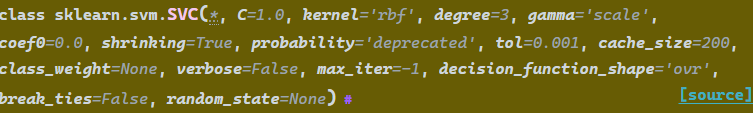

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.pipeline import Pipeline
from tqdm import tqdm

In [4]:
df = pd.read_csv("../Day5/Vehicle.csv")
df.head()

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus


In [5]:
X, y = df.drop("Class",axis=1), df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [8]:
Cs = np.linspace(0.001,10,20)
scaler = StandardScaler()
dfs = ['ovo','ovr']
scores = []
for c in tqdm(Cs):
    for f in dfs:
        svm = SVC(kernel="linear",C=c,decision_function_shape=f)
        pipe = Pipeline([("scaler",scaler),("SVM",svm)])
        pipe.fit(X_train,y_train)
        y_pred = pipe.predict(X_test)
        scores.append([c,f,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["C","f","Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 20/20 [00:02<00:00,  9.64it/s]


,C,f,Score
15,3.684842,ovr,0.807087
8,2.106053,ovo,0.807087
9,2.106053,ovr,0.807087
10,2.632316,ovo,0.807087
11,2.632316,ovr,0.807087
14,3.684842,ovo,0.807087
16,4.211105,ovo,0.803150
25,6.316158,ovr,0.803150
24,6.316158,ovo,0.803150
23,5.789895,ovr,0.803150


In [9]:

df_scores.nlargest(1,"Score")

,C,f,Score
8,2.106053,ovo,0.807087


In [ ]:
# 

In [12]:
Cs = np.linspace(0.001,10,20)
Gs = np.linspace(0.1,10,20)
scaler = StandardScaler()
dfs = ['ovo','ovr']
scores = []
for c in tqdm(Cs):
    for f in dfs:
        for g in Gs:
            svm = SVC(kernel="rbf",C=c,decision_function_shape=f, gamma=g)
            pipe = Pipeline([("scaler",scaler),("SVM",svm)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([c,f,g,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["C","f","g","Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 20/20 [01:06<00:00,  3.31s/it]


,C,f,g,Score
380,4.737368,ovr,0.100000,0.803150
360,4.737368,ovo,0.100000,0.803150
400,5.263632,ovo,0.100000,0.799213
280,3.684842,ovo,0.100000,0.799213
300,3.684842,ovr,0.100000,0.799213
...,...,...,...,...
49,0.527263,ovo,4.789474,0.255906
50,0.527263,ovo,5.310526,0.255906
51,0.527263,ovo,5.831579,0.255906
52,0.527263,ovo,6.352632,0.255906


In [13]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    "SVM__C": np.linspace(0.001, 10, 20),
    "SVM__gamma": np.linspace(0.1, 10, 20),
    "SVM__decision_function_shape": ["ovo", "ovr"],
    "SVM__kernel": ["rbf"]
}

# Create the pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("SVM", SVC())
])

# Set up GridSearchCV (cv=5 uses 5-fold cross-validation)
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

# Results
print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Score:", grid.best_score_)

# Convert all results to a DataFrame if you want to inspect them all
df_scores = pd.DataFrame(grid.cv_results_)

Best Parameters: {'SVM__C': 5.263631578947369, 'SVM__decision_function_shape': 'ovo', 'SVM__gamma': 0.1, 'SVM__kernel': 'rbf'}
Best Cross-Validation Score: 0.8023643355647344


In [14]:
df_scores

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_SVM__C,param_SVM__decision_function_shape,param_SVM__gamma,param_SVM__kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.448331,0.005500,0.025464,0.002618,0.001,ovo,0.100000,rbf,"{'SVM__C': 0.001, 'SVM__decision_function_shap...",0.260504,0.260504,0.254237,0.254237,0.330508,0.271998,0.029389,699
1,0.441185,0.008093,0.025228,0.001817,0.001,ovo,0.621053,rbf,"{'SVM__C': 0.001, 'SVM__decision_function_shap...",0.260504,0.260504,0.254237,0.254237,0.305085,0.266914,0.019290,701
2,0.424703,0.008055,0.016582,0.002384,0.001,ovo,1.142105,rbf,"{'SVM__C': 0.001, 'SVM__decision_function_shap...",0.260504,0.260504,0.254237,0.254237,0.296610,0.265219,0.015944,739
3,0.128326,0.132299,0.022097,0.004972,0.001,ovo,1.663158,rbf,"{'SVM__C': 0.001, 'SVM__decision_function_shap...",0.260504,0.260504,0.254237,0.254237,0.279661,0.261829,0.009346,741
4,0.048428,0.003870,0.015222,0.002547,0.001,ovo,2.184211,rbf,"{'SVM__C': 0.001, 'SVM__decision_function_shap...",0.260504,0.260504,0.254237,0.254237,0.271186,0.260134,0.006196,743
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,0.051489,0.000768,0.013496,0.000682,10.000,ovr,7.915789,rbf,"{'SVM__C': 10.0, 'SVM__decision_function_shape...",0.344538,0.310924,0.322034,0.389831,0.305085,0.334482,0.030785,549
796,0.052699,0.002277,0.013416,0.000488,10.000,ovr,8.436842,rbf,"{'SVM__C': 10.0, 'SVM__decision_function_shape...",0.361345,0.310924,0.322034,0.398305,0.296610,0.337844,0.037102,513
797,0.051755,0.000507,0.013211,0.000600,10.000,ovr,8.957895,rbf,"{'SVM__C': 10.0, 'SVM__decision_function_shape...",0.268908,0.344538,0.322034,0.262712,0.296610,0.298960,0.031088,625
798,0.050746,0.002543,0.013220,0.000678,10.000,ovr,9.478947,rbf,"{'SVM__C': 10.0, 'SVM__decision_function_shape...",0.260504,0.260504,0.330508,0.262712,0.288136,0.280473,0.027112,663
